# Tema 17 · Backpropagation: cómo aprende una red

La regla de la cadena aplicada con orden, programada desde cero.

Este cuaderno es el tema 17 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/17-backpropagation-como-aprende-una-red/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

En el tema 16 armaste una red que resuelve XOR eligiendo sus pesos a mano. Con 9 pesos todavía se puede adivinar; con mil, o con los millones de una red de verdad, es imposible. Para entrenar una red con descenso de gradiente, como en el tema 6, necesitamos la derivada de la pérdida respecto de **cada uno** de sus pesos. ¿Cómo se calculan todas esas derivadas sin pasar la vida haciéndolo?

Una idea es la derivada numérica del tema 5: mover un peso un poquito, volver a calcular la pérdida y ver cuánto cambió. Funciona, pero cuesta dos cálculos completos de la red **por cada peso**. Con un millón de pesos serían dos millones de pasadas para dar **un solo** paso de descenso.

La respuesta se llama **backpropagation** (retropropagación): una forma ordenada de aplicar la regla de la cadena que obtiene **todas** las derivadas con una pasada hacia adelante y una hacia atrás, sin importar cuántos pesos haya. Es lo que hace PyTorch por dentro cada vez que entrena una red, y en este tema lo vas a programar tú.

En este tema vas a:

- dibujar el **grafo computacional** de una expresión y propagar por él los valores hacia adelante y los gradientes hacia atrás;
- programar un pequeño **motor de autograd** con suma, multiplicación, `tanh` y `relu`;
- entrenar con ese motor una red pequeña que separa dos medias lunas;
- comprobar cualquier gradiente con **diferencias finitas**, la derivada numérica del tema 5.

Necesitas la regla de la cadena con engranajes y la derivada numérica centrada del tema 5, el descenso de gradiente del tema 6 y las neuronas y capas del tema 16.

## Actividad: el grafo vivo

Abajo está la expresión *L* = (*a*·*b* + *c*)² dibujada como un **grafo**: cada caja es un número y cada flecha dice de dónde sale. A la izquierda están las entradas *a*, *b* y *c*, que puedes cambiar. En el medio, los resultados intermedios *d* = *a*·*b* y *e* = *d* + *c*. A la derecha, la salida *L*. El recuadro coral marca el paso en el que va el cálculo.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/17-backpropagation-como-aprende-una-red/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pulsa «Adelante». Mira cómo los valores viajan de izquierda a derecha, una caja a la vez, hasta llegar a *L*.
2. Pulsa «Atrás». Ahora viajan los **gradientes**, de derecha a izquierda. Lee la regla que aparece en cada paso: ¿qué hace la caja de la suma con el gradiente que le llega? ¿Y la de la multiplicación?
3. Elige *a* y pulsa «Empujar». La entrada sube 0,01. Compara cuánto cambió *L* con el gradiente de *a* multiplicado por 0,01. Repite con *b* y con *c*.
4. Cambia *c* por 6 y vuelve a pulsar «Adelante» y «Atrás». ¿Por qué ahora todos los gradientes son cero? Empuja cualquier entrada: *L* casi no cambia, porque *L* = 0 es el punto más bajo posible, el fondo del valle.

Lo que acabas de hacer es el tema en pequeño: **hacia adelante se calculan los valores; hacia atrás, cada caja multiplica el gradiente que le llega por su gradiente local y lo pasa a sus entradas.** El gradiente de una entrada dice cuánto cambia la salida si esa entrada se mueve un poquito.

## El grafo computacional

Cualquier cálculo, por largo que sea, está hecho de operaciones pequeñas: sumas, multiplicaciones, potencias. Si le ponemos nombre a cada resultado intermedio, la expresión de la actividad queda así:

$$d = a \cdot b \qquad e = d + c \qquad L = {e}^{2}$$

Ese esquema de cajas y flechas es el **grafo computacional**. Calcularlo de izquierda a derecha es el **paso hacia adelante**. Con *a* = 2, *b* = −3 y *c* = 10:

In [ ]:
# Las entradas
a, b, c = 2.0, -3.0, 10.0

# Hacia adelante: un nodo a la vez, de izquierda a derecha
d = a * b
e = d + c
L = e ** 2
print(f"Adelante:  d = {d}   e = {e}   L = {L}")

Adelante:  d = -6.0   e = 4.0   L = 16.0


Ahora queremos saber cuánto cambia *L* si movemos un poquito cada entrada: las derivadas ∂*L*/∂*a*, ∂*L*/∂*b* y ∂*L*/∂*c*. A cada una la vamos a llamar el **gradiente** de esa entrada (estrictamente, el gradiente es el vector con todas ellas, como en el tema 5; aquí cada número es una componente).

## Hacia atrás, caja por caja

En el tema 5 viste la regla de la cadena con engranajes: si *x* mueve a *u* y *u* mueve a *y*, las velocidades se multiplican.

$$\frac{d y}{d x} = \frac{d y}{d u} \cdot \frac{d u}{d x}$$

En un grafo hay muchos engranajes en fila, y la regla se aplica de atrás hacia adelante, una caja a la vez. Cada caja solo necesita saber dos cosas:

- el **gradiente que llega**: cuánto cambia *L* si cambia la salida de esta caja (ya lo calculó la caja de la derecha);
- su **gradiente local**: cuánto cambia la salida de esta caja si cambia una de sus entradas. Solo depende de la operación de la caja, no del resto del grafo.

Y hace una sola cuenta: **gradiente de la entrada = gradiente que llega × gradiente local**. Para las operaciones de nuestro grafo, los gradientes locales son:

| Caja | Gradiente local respecto de cada entrada | Qué hace con el gradiente que llega |
|---|---|---|
| *e*² | 2*e* | Lo multiplica por 2*e* |
| *d* + *c* | 1 y 1 | Lo **copia** igual a las dos entradas |
| *a* · *b* | *b* (para *a*) y *a* (para *b*) | Lo multiplica por **la otra** entrada |

Se empieza por la salida: ∂*L*/∂*L* = 1 (si *L* sube 0,01, *L* sube 0,01). Después se recorre el grafo al revés:

In [ ]:
# Hacia atrás: de derecha a izquierda.
# En cada nodo: gradiente que llega × gradiente local
dL_dL = 1.0
dL_de = dL_dL * 2 * e      # caja e²: local 2e
dL_dd = dL_de * 1          # caja d + c: local 1 (copia)
dL_dc = dL_de * 1
dL_da = dL_dd * b          # caja a·b: local respecto de a es b
dL_db = dL_dd * a          # y respecto de b es a
print(f"dL/de = {dL_de}   dL/dd = {dL_dd}   dL/dc = {dL_dc}")
print(f"dL/da = {dL_da}   dL/db = {dL_db}")

dL/de = 8.0   dL/dd = 8.0   dL/dc = 8.0
dL/da = -24.0   dL/db = 16.0


Lee los signos. ∂*L*/∂*a* = −24: si *a* sube un poquito, *L* **baja** 24 veces ese poquito. Tiene sentido: *a* se multiplica por *b* = −3, así que subir *a* achica *e* = 4, y *L* = *e*² baja. En cambio ∂*L*/∂*c* = 8: subir *c* agranda *e* y *L* sube.

Antes de creer en una cuenta hecha a mano, se comprueba. La derivada numérica centrada del tema 5, con *h* = 10⁻⁶, tiene que dar casi lo mismo:

In [ ]:
def calcular_L(a, b, c):
    return (a * b + c) ** 2

h = 1e-6
dL_da_num = (calcular_L(a + h, b, c) - calcular_L(a - h, b, c)) / (2 * h)
dL_db_num = (calcular_L(a, b + h, c) - calcular_L(a, b - h, c)) / (2 * h)
dL_dc_num = (calcular_L(a, b, c + h) - calcular_L(a, b, c - h)) / (2 * h)
print("Numéricas:", round(dL_da_num, 4), round(dL_db_num, 4),
      round(dL_dc_num, 4))

Numéricas: -24.0 16.0 8.0


Coinciden. Dibujemos el grafo con los valores y los gradientes anotados. Cada caja muestra su valor (calculado hacia adelante) y, debajo, su gradiente (calculado hacia atrás):

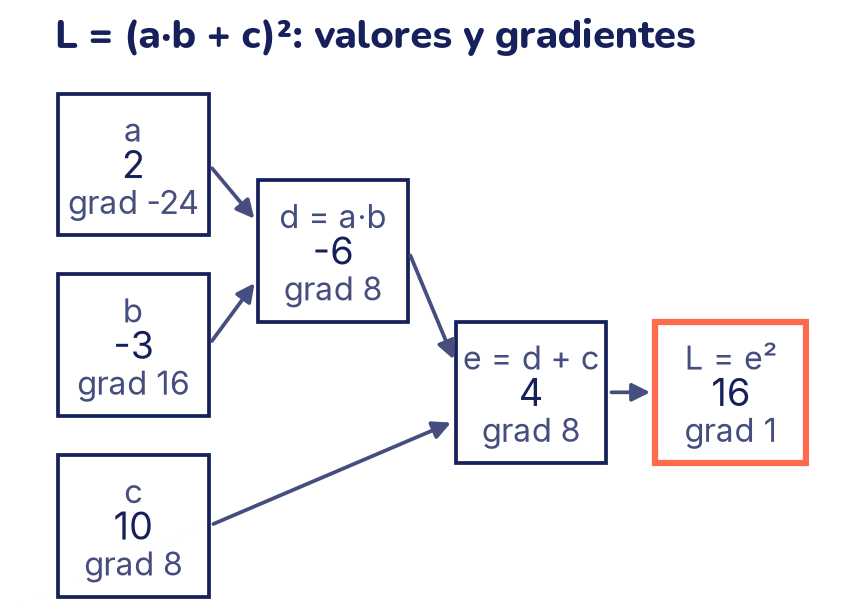

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Cada nodo: posición (x, y), rótulo, valor y gradiente
nodos = {
    "a": (0.5, 2.75, "a", a, dL_da),
    "b": (0.5, 1.6, "b", b, dL_db),
    "c": (0.5, 0.45, "c", c, dL_dc),
    "d": (1.77, 2.2, "d = a·b", d, dL_dd),
    "e": (3.03, 1.3, "e = d + c", e, dL_de),
    "L": (4.3, 1.3, "L = e²", L, dL_dL),
}
# Las flechas: de dónde sale cada número
aristas = [("a", "d"), ("b", "d"), ("d", "e"), ("c", "e"), ("e", "L")]

fig, eje = plt.subplots()
for origen, destino in aristas:
    x0, y0 = nodos[origen][:2]
    x1, y1 = nodos[destino][:2]
    # La flecha llega un poco arriba o abajo, según de dónde viene
    llegada = y1 + 0.18 * np.sign(y0 - y1)
    eje.annotate("", xy=(x1 - 0.48, llegada), xytext=(x0 + 0.48, y0),
                 arrowprops=dict(arrowstyle="-|>", color="C2", lw=1.5))
for nombre, (x, y, rotulo, valor, grad) in nodos.items():
    # Solo la salida L va resaltada
    borde = "C1" if nombre == "L" else "C0"
    eje.add_patch(plt.Rectangle((x - 0.48, y - 0.45), 0.96, 0.9,
                                facecolor="white", edgecolor=borde,
                                linewidth=2.5 if nombre == "L" else 1.5))
    eje.text(x, y + 0.22, rotulo, ha="center", va="center", fontsize=13,
             color="C2")
    eje.text(x, y, f"{valor:g}", ha="center", va="center",
             fontsize=15, fontweight="semibold")
    eje.text(x, y - 0.24, f"grad {grad:g}", ha="center", va="center",
             fontsize=13, color="C2")
eje.set_xlim(0, 4.8)
# Un poco por debajo de 0 para que no se corte el borde de la caja c
eje.set_ylim(-0.05, 3.3)
eje.set_aspect("equal")
eje.axis("off")
eje.set_title("L = (a·b + c)²: valores y gradientes")
plt.show()

Fíjate en lo que **no** tuvimos que hacer: nunca escribimos la fórmula completa de ∂*L*/∂*a*. Cada caja hizo una cuenta local y fácil, y el gradiente se fue armando solo al pasar de caja en caja. Por eso el método escala: una red con millones de pesos es un grafo con millones de cajas, pero cada caja sigue siendo una suma, una multiplicación o una activación.

### Dos caminos: los gradientes se suman

¿Qué pasa si una variable entra en el grafo por dos caminos? Por ejemplo, en *f* = *x*·*y* + *x*, la *x* va a la multiplicación y también a la suma. Si *x* sube un poquito, *f* cambia **por los dos caminos a la vez**, y los dos efectos se suman. Por el camino de la multiplicación llega *y*; por el de la suma llega 1; en total ∂*f*/∂*x* = *y* + 1.

Por eso, al programar backpropagation, cada caja **suma** su aporte al gradiente de sus entradas (`grad += ...`) en lugar de reemplazarlo (`grad = ...`). Si se reemplaza, el último camino borra a los demás y el gradiente sale mal sin ningún mensaje de error. En las redes neuronales esto pasa todo el tiempo: cada entrada llega a todas las neuronas de la primera capa, y cada peso se usa una vez por ejemplo.

## Lo que necesitas de Python

La clase `Valor` de la próxima sección usa cuatro herramientas de Python que todavía no vimos. Aquí va cada una con un ejemplo mínimo.

**Métodos especiales.** En el tema 2 viste que `__init__`, con dos guiones bajos a cada lado, se ejecuta solo al crear un objeto. Hay más métodos con ese tipo de nombre, y Python los llama por su cuenta: `__add__` cuando escribes `p + q`, `__mul__` con `p * q`, `__pow__` con `p ** 2`, `__neg__` con `-p`, `__sub__` con `p - q` y `__repr__` cuando haces `print(p)`. Así una clase propia puede usar los signos de siempre:

In [ ]:
class Punto:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __add__(self, otro):          # Python lo llama con p + q
        return Punto(self.x + otro.x, self.y + otro.y)

    def __repr__(self):               # lo que muestra print(p)
        return f"Punto({self.x}, {self.y})"

p = Punto(1, 2) + Punto(10, 20)
print(p)

Punto(11, 22)


Con `3 + p`, en cambio, el que va a la izquierda es un número, y los números no saben sumar un `Punto`. Entonces Python prueba con el de la derecha y llama a `p.__radd__(3)` (la «r» es de *right*, derecha). Por eso `Valor` también define `__radd__` y `__rmul__`.

**`isinstance`.** `isinstance(cosa, Clase)` responde `True` si `cosa` es un objeto de esa clase. `Valor` lo usa para aceptar números sueltos: si le llega un 3 en lugar de un `Valor`, lo envuelve.

In [ ]:
print(isinstance(p, Punto), isinstance(3, Punto), isinstance(3, int))

True False True


**Funciones dentro de funciones que recuerdan variables.** Una función se puede definir dentro de otra y devolverse como cualquier otro valor. La de adentro **recuerda** las variables de la de afuera, aunque la de afuera ya haya terminado:

In [ ]:
def crear_multiplicador(k):
    def multiplicar(x):
        return k * x                  # usa la k de afuera
    return multiplicar                # sin paréntesis: la función misma

doble = crear_multiplicador(2)
triple = crear_multiplicador(3)
print(doble(5), triple(5))

10 15


Cada llamada a `crear_multiplicador` fabrica una función nueva con su propia `k`. En `Valor` pasa lo mismo: cada operación fabrica una función `_atras` que recuerda sus propios `self`, `otro` y `salida`, y que se llama mucho después, al ir hacia atrás. `lambda: None` (la `lambda` del tema 2) es una función sin argumentos que no hace nada: es el `_atras` de los valores que no salieron de ninguna operación.

**Recursión y `set()`.** Una función **recursiva** se llama a sí misma con un pedazo más chico del problema, hasta llegar a un caso que se resuelve directo. Sirve para recorrer cosas anidadas, como listas de listas o, más adelante, un grafo. Y `set()` crea un **conjunto** vacío: guarda cosas sin repetirlas, y `x in conjunto` responde rápido si ya está.

In [ ]:
def contar_numeros(cosa):
    """Cuenta los números que hay dentro de listas de listas."""
    if not isinstance(cosa, list):
        return 1                      # caso directo: un número suelto
    total = 0
    for parte in cosa:
        total += contar_numeros(parte)  # se llama a sí misma
    return total

print(contar_numeros([1, [2, 3], [[4], 5]]))

vistos = set()
for letra in "banana":
    vistos.add(letra)                 # una letra repetida no se agrega
print(len(vistos), "a" in vistos, "z" in vistos)

5
3 True False


## Un motor de autograd: la clase `Valor`

Hacer el recorrido hacia atrás a mano sirve para entender, pero no para una red. Vamos a escribir una clase `Valor` que guarda un número y **recuerda de dónde salió**: de qué otros valores y con qué operación. Con eso puede recorrer el grafo hacia atrás ella sola. A esto se le llama **autograd** (diferenciación automática) y es exactamente lo que hacen PyTorch y las demás librerías de redes, solo que con tablas de números en lugar de números sueltos.

La idea y la forma de esta clase están inspiradas en [micrograd](https://github.com/karpathy/micrograd), un motor de autograd mínimo que Andrej Karpathy escribió para enseñar. El código de aquí es una versión propia, en español.

Cada `Valor` guarda:

- `dato`: el número, calculado hacia adelante;
- `grad`: la derivada de la salida final respecto de este número; empieza en 0 y se llena hacia atrás;
- `_hijos`: los valores de los que salió;
- `_atras`: una pequeña función que sabe pasar el gradiente que llega a los hijos, con la regla local de su operación.

In [ ]:
import math

class Valor:
    """Un número que recuerda de dónde salió y guarda su gradiente."""

    def __init__(self, dato, hijos=(), op=""):
        self.dato = dato              # el número (hacia adelante)
        self.grad = 0.0               # dSalida/dEste (hacia atrás)
        self._hijos = hijos           # los Valor de los que salió
        self._op = op                 # la operación que lo creó
        self._atras = lambda: None    # pasa el gradiente a los hijos

    def __repr__(self):
        return f"Valor(dato={self.dato:.4g}, grad={self.grad:.4g})"

    def __add__(self, otro):
        otro = otro if isinstance(otro, Valor) else Valor(otro)
        salida = Valor(self.dato + otro.dato, (self, otro), "+")
        def _atras():
            # Suma: el gradiente que llega se copia a las dos entradas
            self.grad += salida.grad
            otro.grad += salida.grad
        salida._atras = _atras
        return salida

    def __mul__(self, otro):
        otro = otro if isinstance(otro, Valor) else Valor(otro)
        salida = Valor(self.dato * otro.dato, (self, otro), "*")
        def _atras():
            # Multiplicación: cada entrada recibe la otra entrada
            self.grad += otro.dato * salida.grad
            otro.grad += self.dato * salida.grad
        salida._atras = _atras
        return salida

    def __pow__(self, k):
        # k es un número fijo (2, 3, -1...), no un Valor
        salida = Valor(self.dato ** k, (self,), f"**{k}")
        def _atras():
            self.grad += k * self.dato ** (k - 1) * salida.grad
        salida._atras = _atras
        return salida

    def tanh(self):
        t = math.tanh(self.dato)
        salida = Valor(t, (self,), "tanh")
        def _atras():
            # La derivada de tanh es 1 - tanh²
            self.grad += (1 - t ** 2) * salida.grad
        salida._atras = _atras
        return salida

    def relu(self):
        salida = Valor(max(0.0, self.dato), (self,), "relu")
        def _atras():
            # Pendiente 1 si la entrada fue positiva, 0 si no
            self.grad += (self.dato > 0) * salida.grad
        salida._atras = _atras
        return salida

    # Lo demás se arma con lo anterior
    def __neg__(self):                # -x
        return self * -1

    def __sub__(self, otro):          # x - y
        return self + (-otro)

    def __radd__(self, otro):         # 3 + x
        return self + otro

    def __rmul__(self, otro):         # 3 * x
        return self * otro

    def retropropagar(self):
        """Llena el grad de todos los Valor de los que depende este."""
        # Orden topológico: cada nodo va después de todos sus hijos
        orden, vistos = [], set()
        def visitar(v):
            if v not in vistos:
                vistos.add(v)
                for hijo in v._hijos:
                    visitar(hijo)
                orden.append(v)
        visitar(self)
        # dSalida/dSalida = 1, y de ahí hacia atrás
        self.grad = 1.0
        for v in reversed(orden):
            v._atras()

Tres ideas de esta clase merecen una segunda lectura:

1. **Python llama a `__add__` cuando escribes `x + y`**, a `__mul__` cuando escribes `x * y` y a `__pow__` con `x ** 2`. Por eso, con objetos `Valor`, una expresión normal de Python va armando el grafo sin que te des cuenta.
2. **Cada operación deja anotada su regla local** en `_atras`, en el momento de calcular hacia adelante. Son las mismas reglas de la tabla: la suma copia, la multiplicación pasa la otra entrada, la potencia usa *k*·*x*<sup>*k*−1</sup>, `tanh` usa 1 − tanh² y `relu` deja pasar el gradiente solo si la entrada fue positiva.
3. **`retropropagar` recorre el grafo en el orden correcto.** Una caja solo puede pasar su gradiente cuando ya recibió todo lo que le llega. El **orden topológico** pone cada nodo después de todos los nodos de los que salió. La función recursiva `visitar` lo arma así: antes de anotar un nodo, visita a sus hijos, y el conjunto `vistos` evita anotar dos veces el mismo. Para *L* = (*a*·*b* + *c*)², con los nombres del grafo, el orden queda [*a*, *b*, *d*, *c*, *e*, *L*]: cada nodo aparece después de los que necesita. Recorrido al revés, [*L*, *e*, *c*, *d*, *b*, *a*], va desde la salida hasta las entradas sin saltarse a nadie: cuando le toca a *d*, *e* ya le pasó todo su gradiente.

Probemos con la expresión de la actividad:

In [ ]:
a = Valor(2.0)
b = Valor(-3.0)
c = Valor(10.0)
L = (a * b + c) ** 2
L.retropropagar()
print("L =", L)
print("a =", a)
print("b =", b)
print("c =", c)

L = Valor(dato=16, grad=1)
a = Valor(dato=2, grad=-24)
b = Valor(dato=-3, grad=16)
c = Valor(dato=10, grad=8)


Los mismos gradientes que a mano: −24, 16 y 8. Y el caso de una variable usada dos veces, *f* = *x*·*y* + *x* con *x* = 3 e *y* = −2, donde esperamos ∂*f*/∂*x* = *y* + 1 = −1:

In [ ]:
x = Valor(3.0)
y = Valor(-2.0)
f = x * y + x
f.retropropagar()
print("f =", f.dato, "  df/dx =", x.grad, "  df/dy =", y.grad)

f = -3.0   df/dx = -1.0   df/dy = 3.0


Los dos caminos de *x* sumaron sus aportes (−2 por la multiplicación y +1 por la suma), gracias al `+=`.

## Verificar gradientes con diferencias finitas

Un motor de autograd puede tener un error de signo o un gradiente local mal escrito y seguir calculando números que parecen razonables. La forma de atraparlo es la **verificación numérica de gradientes**: comparar cada gradiente con la diferencia centrada del tema 5. Es lenta (dos cálculos por entrada), pero no hace falta que sea rápida: solo se usa para comprobar.

Probemos con una expresión que usa todas las operaciones del motor:

In [ ]:
def expresion(x, y, z):
    """Una expresión cualquiera que usa todo lo que sabe el motor."""
    return (x * y + z.tanh()) * (x - y).relu() + x ** 3

def gradiente_numerico(f, numeros, h=1e-6):
    """Derivada centrada de f respecto de cada número de la lista."""
    grads = []
    for i in range(len(numeros)):
        mas = list(numeros)
        menos = list(numeros)
        mas[i] += h
        menos[i] -= h
        # f(*lista) pasa cada elemento de la lista como un argumento
        f_mas = f(*[Valor(v) for v in mas]).dato
        f_menos = f(*[Valor(v) for v in menos]).dato
        grads.append((f_mas - f_menos) / (2 * h))
    return grads

numeros = [1.5, -0.5, 0.8]
entradas = [Valor(v) for v in numeros]
expresion(*entradas).retropropagar()

for nombre, v, g_num in zip("xyz", entradas,
                            gradiente_numerico(expresion, numeros)):
    print(f"{nombre}:  autograd = {v.grad:.6f}   numérico = {g_num:.6f}"
          f"   diferencia = {abs(v.grad - g_num):.1e}")

x:  autograd = 5.664037   numérico = 5.664037   diferencia = 6.6e-10
y:  autograd = 3.085963   numérico = 3.085963   diferencia = 1.1e-10
z:  autograd = 1.118110   numérico = 1.118110   diferencia = 3.5e-11


Las diferencias son del orden de una millonésima o menos: el error normal de redondeo de la derivada numérica. Si alguna regla local estuviera mal, la diferencia sería del tamaño del gradiente mismo, no de 10⁻⁶. En los ejercicios vas a ver qué pasa cuando hay un error.

## Una red neuronal encima del motor

Con `Valor` ya podemos construir las piezas del tema 16, ahora con gradientes. Una **neurona** tiene un peso por entrada y un término independiente *b*, calcula la suma ponderada y le aplica una activación. Una **capa** es una lista de neuronas que reciben las mismas entradas. Un **MLP** es una lista de capas, donde la salida de una es la entrada de la siguiente.

In [ ]:
import random

class Neurona:
    """Suma ponderada de las entradas, más b, y luego tanh."""

    def __init__(self, n_entradas):
        self.w = [Valor(random.uniform(-1, 1)) for _ in range(n_entradas)]
        self.b = Valor(0.0)

    def __call__(self, x):
        z = self.b
        for wi, xi in zip(self.w, x):
            z = z + wi * xi           # cada + y cada * arma el grafo
        return z.tanh()

    def parametros(self):
        return self.w + [self.b]

class Capa:
    """Varias neuronas que reciben las mismas entradas."""

    def __init__(self, n_entradas, n_neuronas):
        self.neuronas = [Neurona(n_entradas) for _ in range(n_neuronas)]

    def __call__(self, x):
        salidas = [neurona(x) for neurona in self.neuronas]
        return salidas[0] if len(salidas) == 1 else salidas

    def parametros(self):
        return [p for n in self.neuronas for p in n.parametros()]

class MLP:
    """Capas en fila: la salida de una es la entrada de la siguiente."""

    def __init__(self, anchos):
        self.capas = [Capa(anchos[i], anchos[i + 1])
                      for i in range(len(anchos) - 1)]

    def __call__(self, x):
        for capa in self.capas:
            x = capa(x)
        return x

    def parametros(self):
        return [p for capa in self.capas for p in capa.parametros()]

random.seed(0)                        # pesos iniciales reproducibles
modelo = MLP([2, 8, 1])               # 2 entradas, 8 ocultas, 1 salida
print("Parámetros:", len(modelo.parametros()))
print("Salida para el punto (1, 0):", modelo([1.0, 0.0]))

Parámetros: 33
Salida para el punto (1, 0): Valor(dato=0.6908, grad=0)


La red 2-8-1 tiene 2·8 + 8 = 24 parámetros en la capa oculta y 8 + 1 = 9 en la de salida: 33 en total. Cada uno es un `Valor` con su `grad`.

### Los datos y la pérdida

Usamos `make_moons`, las dos medias lunas sintéticas del tema 8. Nuestro motor es Python puro y cada número es un objeto, así que es **lento**: con 30 puntos ya tarda unos segundos en entrenar. Una red real hace lo mismo con tablas enteras de números a la vez (eso lo resuelve PyTorch en el tema 18).

La salida de la red es una `tanh`, que da números entre −1 y 1. Por eso anotamos las clases como −1 y +1, y la red predice la clase +1 cuando su salida es positiva. Como pérdida usamos el **MSE** del tema 6 entre la salida y la clase. (En el tema 16 viste que para clasificar lo habitual es la entropía cruzada; para eso el motor necesitaría `exp` y `log`. Con esta red pequeña, el MSE funciona bien y no necesita nada nuevo.)

In [ ]:
from sklearn.datasets import make_moons

X_lunas, y_lunas = make_moons(n_samples=30, noise=0.1, random_state=0)
y_signo = 2 * y_lunas - 1             # clases -1 y +1, como la tanh

def perdida_y_exactitud(modelo, X, y):
    """MSE de la red sobre todos los puntos, y la fracción de aciertos."""
    salidas = [modelo(list(fila)) for fila in X]
    perdida = sum((s - yi) ** 2 for s, yi in zip(salidas, y))
    perdida = perdida * (1 / len(y))
    aciertos = sum((s.dato > 0) == (yi > 0) for s, yi in zip(salidas, y))
    return perdida, aciertos / len(y)

perdida, exactitud = perdida_y_exactitud(modelo, X_lunas, y_signo)
print(f"Antes de entrenar: pérdida = {perdida.dato:.4f}"
      f"   aciertos = {exactitud:.0%}")

Antes de entrenar: pérdida = 0.6989   aciertos = 70%


### El bucle de entrenamiento

Es el descenso de gradiente del tema 6, ahora con 33 parámetros. En cada **época** la red ve los 30 puntos una vez y hace cuatro cosas:

1. **Adelante:** calcular la pérdida con los parámetros actuales.
2. **Poner los gradientes en cero.** Como `_atras` suma con `+=`, los gradientes de la época anterior se mezclarían con los nuevos si no se borran.
3. **Atrás:** `retropropagar()` llena el `grad` de los 33 parámetros con una sola pasada.
4. **Paso:** mover cada parámetro un poco en contra de su gradiente.

In [ ]:
tasa = 0.5
perdidas = []                         # la pérdida de cada época
fotos = {}                            # los parámetros en algunas épocas

for epoca in range(201):
    perdida, exactitud = perdida_y_exactitud(modelo, X_lunas, y_signo)
    perdidas.append(perdida.dato)
    if epoca in [0, 20, 100, 200]:
        fotos[epoca] = [p.dato for p in modelo.parametros()]
    if epoca % 50 == 0 or epoca == 20:
        print(f"Época {epoca:3d}:   pérdida = {perdida.dato:.4f}"
              f"   aciertos = {exactitud:.0%}")
    if epoca == 200:
        break                         # la última época solo mide
    for p in modelo.parametros():     # 2. gradientes en cero
        p.grad = 0.0
    perdida.retropropagar()           # 3. hacia atrás
    for p in modelo.parametros():     # 4. un paso en contra
        p.dato -= tasa * p.grad

Época   0:   pérdida = 0.6989   aciertos = 70%
Época  20:   pérdida = 0.3638   aciertos = 90%
Época  50:   pérdida = 0.2147   aciertos = 93%
Época 100:   pérdida = 0.1052   aciertos = 97%
Época 150:   pérdida = 0.0711   aciertos = 97%
Época 200:   pérdida = 0.0514   aciertos = 100%


La pérdida baja de 0,70 a 0,05 y la red termina acertando los 30 puntos. Así se ve la curva de pérdida:

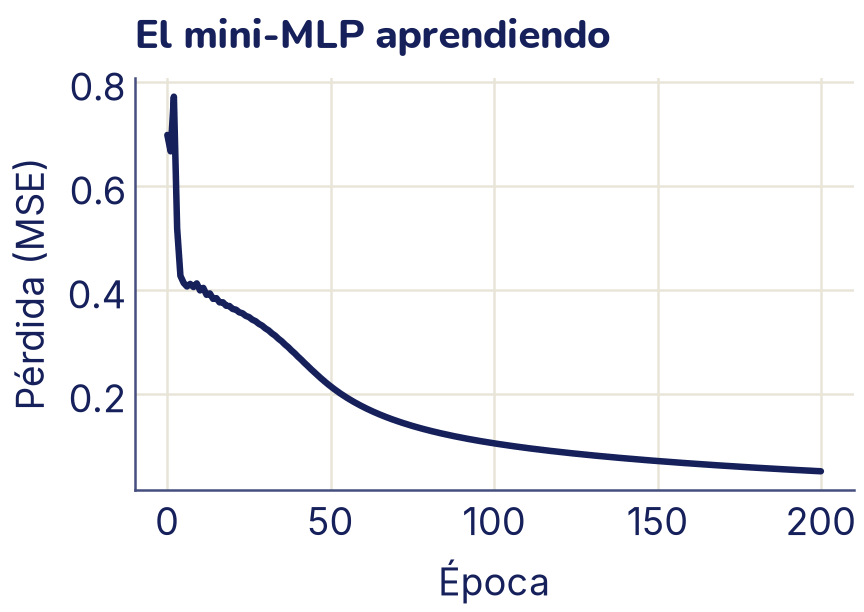

In [ ]:
plt.plot(perdidas, color="C0")
plt.xlabel("Época")
plt.ylabel("Pérdida (MSE)")
plt.title("El mini-MLP aprendiendo")
plt.show()

En las primeras épocas la pérdida sube un poco antes de caer: con una tasa de 0,5 los primeros pasos son algo largos, como los rebotes del tema 6. Enseguida se acomoda. Después hay un tramo casi plano cerca de 0,4 y una segunda bajada: es cuando la red empieza a doblar la frontera, como se ve abajo.

Con las fotos de los parámetros podemos ver cómo cambió la **frontera de decisión**: la curva donde la salida de la red vale cero. Para dibujarla, cargamos cada foto en la red y la evaluamos en una cuadrícula de puntos del plano.

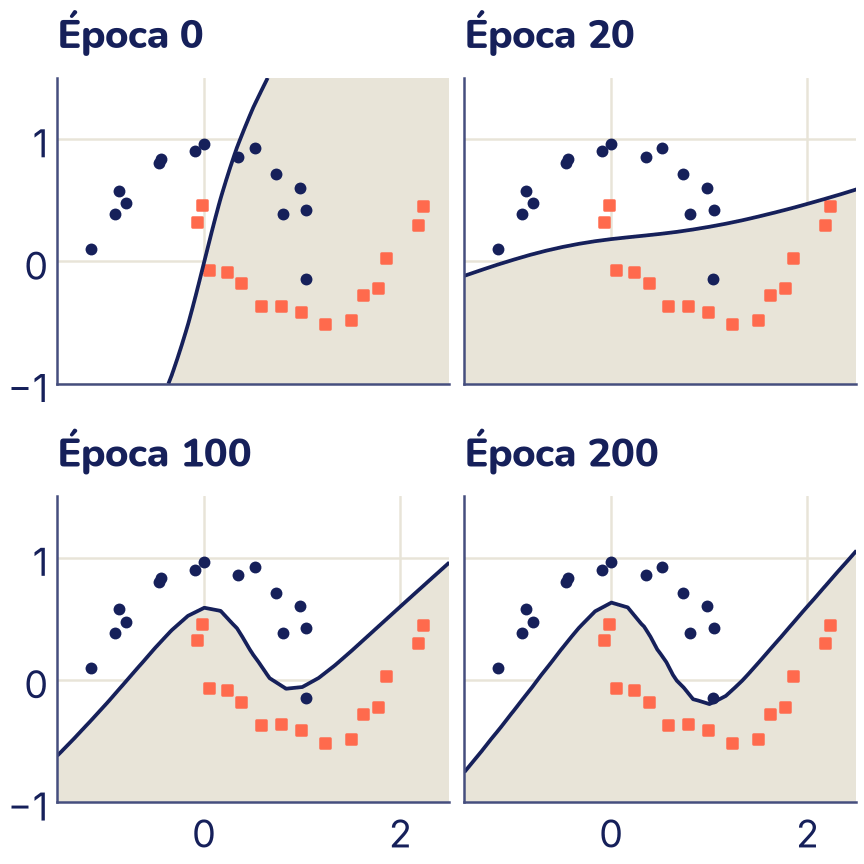

In [ ]:
def cargar(modelo, numeros):
    """Pone en la red los parámetros guardados en una foto."""
    for p, v in zip(modelo.parametros(), numeros):
        p.dato = v

# Una cuadrícula de 25 × 25 puntos que cubre las dos lunas
xs = np.linspace(-1.5, 2.5, 25)
ys = np.linspace(-1.0, 1.5, 25)
A, B = np.meshgrid(xs, ys)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, epoca in zip(ejes.flat, [0, 20, 100, 200]):
    cargar(modelo, fotos[epoca])
    Z = np.array([[modelo([u, v]).dato for u in xs] for v in ys])
    # Fondo: la zona donde la red dice «clase 1»
    eje.contourf(A, B, Z, levels=[0, 1.1], colors="C3")
    eje.contour(A, B, Z, levels=[0], colors="C0", linewidths=1.5)
    eje.scatter(*X_lunas[y_lunas == 0].T, s=14, color="C0", marker="o")
    eje.scatter(*X_lunas[y_lunas == 1].T, s=14, color="C1", marker="s")
    eje.set_title(f"Época {epoca}")
plt.show()
cargar(modelo, fotos[200])            # la red queda como al final

La red empieza con una frontera al azar (los pesos iniciales son aleatorios). En unas pocas épocas aprende la separación más fácil, una curva suave casi recta; después, más despacio, la dobla para dejar del lado correcto las puntas de las lunas, que se meten una en la otra y que ninguna recta puede separar. Cada uno de esos cambios salió de lo mismo: miles de cuentas locales en un grafo, recorridas hacia atrás.

## Una capa entera, con matrices

Nuestro motor maneja números de a uno. En la práctica, una capa densa (tema 16) procesa un **lote** de ejemplos de una vez con un producto de matrices:

$$Z = X W + \mathbf{b}$$

donde *X* tiene una fila por ejemplo y una columna por entrada, y *W* tiene una fila por entrada y una columna por neurona. El paso hacia atrás también se escribe con matrices. Si *G* es el gradiente que llega a *Z* (una tabla del mismo tamaño que *Z*), las reglas son:

$$\frac{\partial L}{\partial W} = {X}^{T} G \qquad \frac{\partial L}{\partial \mathbf{b}} = \text{suma de las filas de } G \qquad \frac{\partial L}{\partial X} = G {W}^{T}$$

No son reglas nuevas: son las de la multiplicación y la suma, hechas para todos los números a la vez. Cada peso *W*<sub>ij</sub> multiplica a la entrada *i* de cada ejemplo, así que su gradiente es «la otra entrada por el gradiente que llega», **sumado sobre todos los ejemplos del lote** (el `+=` de antes, porque el mismo peso se usa una vez por ejemplo). Eso es justo lo que calcula *X*<sup>T</sup>*G*. El término independiente **b** se suma a cada fila, así que recibe la suma de los gradientes de todas las filas. Y una forma rápida de no equivocarse: **cada gradiente tiene la misma forma que lo que deriva**.

Comprobémoslo con una capa de 3 entradas y 4 neuronas con ReLU, un lote de 5 ejemplos y una pérdida sencilla, la mitad de la suma de las salidas al cuadrado (su gradiente respecto de las salidas son las salidas mismas):

In [ ]:
rng = np.random.default_rng(0)
X_capa = rng.normal(size=(5, 3))      # 5 ejemplos, 3 entradas
W = rng.normal(size=(3, 4))           # 3 entradas, 4 neuronas
b_capa = rng.normal(size=4)           # un b por neurona

def perdida_capa(W, b_capa):
    Z = X_capa @ W + b_capa
    S = np.maximum(Z, 0)              # ReLU
    return 0.5 * np.sum(S ** 2)

# Adelante, guardando lo que hará falta atrás
Z = X_capa @ W + b_capa
S = np.maximum(Z, 0)

# Atrás, con matrices
dS = S                                # derivada de 0,5·S² es S
dZ = dS * (Z > 0)                     # ReLU: pasa solo si Z > 0
dW = X_capa.T @ dZ
db = dZ.sum(axis=0)
dX = dZ @ W.T
print("Formas:  W", W.shape, " dW", dW.shape, "  b", b_capa.shape,
      " db", db.shape, "  X", X_capa.shape, " dX", dX.shape)

# Verificación numérica, peso por peso
h = 1e-6
dW_num = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        W_mas, W_menos = W.copy(), W.copy()
        W_mas[i, j] += h
        W_menos[i, j] -= h
        dW_num[i, j] = (perdida_capa(W_mas, b_capa)
                        - perdida_capa(W_menos, b_capa)) / (2 * h)
print("Mayor diferencia en dW:", f"{np.abs(dW - dW_num).max():.1e}")

Formas:  W (3, 4)  dW (3, 4)   b (4,)  db (4,)   X (5, 3)  dX (5, 3)
Mayor diferencia en dW: 6.2e-11


Las fórmulas con matrices dan los mismos gradientes que la derivada numérica. Así funciona por dentro cada capa de PyTorch.

## Gradientes que se desvanecen o explotan

Hacia atrás, el gradiente que llega a la primera capa de una red profunda es un **producto** de gradientes locales, uno por capa. Si la mayoría son menores que 1, el producto se achica muy rápido; si son mayores que 1, crece muy rápido:

In [ ]:
# Un gradiente que cruza 10, 20 o 50 capas,
# con el mismo gradiente local en cada una
for local in [0.25, 0.9, 1.1, 1.5]:
    print(f"local {local}:", "   ".join(
        f"{n} capas: {local ** n:.1e}" for n in [10, 20, 50]))

local 0.25: 10 capas: 9.5e-07   20 capas: 9.1e-13   50 capas: 7.9e-31
local 0.9: 10 capas: 3.5e-01   20 capas: 1.2e-01   50 capas: 5.2e-03
local 1.1: 10 capas: 2.6e+00   20 capas: 6.7e+00   50 capas: 1.2e+02
local 1.5: 10 capas: 5.8e+01   20 capas: 3.3e+03   50 capas: 6.4e+08


- La derivada de la sigmoide vale como mucho 0,25 (tema 16). Con 10 capas de sigmoides, a las primeras les llega menos de una millonésima del gradiente: casi no aprenden. Es el **desvanecimiento del gradiente**, y una de las razones por las que hoy se prefiere ReLU, cuya derivada es 1 donde está activa.
- Con gradientes locales un poco mayores que 1 (por ejemplo, pesos iniciales demasiado grandes), el gradiente **explota**: los pasos se vuelven enormes y la pérdida diverge, como la tasa de aprendizaje demasiado alta del tema 6.

Por eso importan tanto la activación, la inicialización de los pesos y la normalización. Las vas a ver en el tema 19.

## Lo que aprendiste y lo que sigue

- Todo cálculo es un **grafo computacional** de operaciones pequeñas. Hacia adelante se calculan los valores; hacia atrás, los gradientes.
- En cada caja, **gradiente de la entrada = gradiente que llega × gradiente local**. La suma copia el gradiente; la multiplicación pasa la otra entrada.
- Cuando un número se usa por varios caminos, sus gradientes **se suman**: por eso `+=`, y por eso hay que poner los gradientes en cero antes de cada paso.
- Con una clase `Valor` de unas 80 líneas se arma un motor de autograd, y encima, una red que aprende con descenso de gradiente.
- Todo gradiente se puede **verificar** con la derivada numérica centrada, que es lenta pero confiable.
- Con matrices, una capa densa se retropropaga con *X*<sup>T</sup>*G*, la suma de las filas de *G* y *G* *W*<sup>T</sup>. Los productos de muchos gradientes locales pueden **desvanecerse** o **explotar**.

En el tema 18 vas a usar PyTorch, que hace exactamente esto con tensores: `requires_grad` marca los números que necesitan gradiente, `.backward()` es nuestro `retropropagar()` y `zero_grad()` es el bucle que pone los gradientes en cero.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que se definió en la teoría: la clase `Valor`, `gradiente_numerico`, `Neurona`, `Capa`, `MLP`, `modelo` (la red ya entrenada), `X_lunas`, `y_signo`, `perdida_y_exactitud` y `cargar`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Haz primero las cuentas a mano y recién después abre la respuesta: el objetivo es que el recorrido hacia atrás te salga solo.

## Ejercicios

### 1. Backpropagation a mano

Para cada expresión, dibuja el grafo, calcula hacia adelante el valor de cada caja y después, hacia atrás, el gradiente de cada entrada. Comprueba al final con la clase `Valor`.

a) *f* = (*x* + *y*) · *z*, con *x* = 1, *y* = 2 y *z* = −3.

b) *f* = *x* · *y* + *x*, con *x* = 3 e *y* = −2.

c) *f* = tanh(*w* · *x* + *b*), con *w* = 0,5, *x* = 2 y *b* = −1. Es una neurona con una sola entrada.

<details>
<summary>Respuesta</summary>

a) Hacia adelante: *q* = *x* + *y* = 3 y *f* = *q* · *z* = −9. Hacia atrás: la multiplicación pasa la otra entrada, así que ∂*f*/∂*z* = *q* = **3** y ∂*f*/∂*q* = *z* = −3. La suma copia ese −3 a sus dos entradas: ∂*f*/∂*x* = ∂*f*/∂*y* = **−3**.

b) Hacia adelante: *p* = *x* · *y* = −6 y *f* = *p* + *x* = −3. Hacia atrás: la suma copia 1 a *p* y 1 a *x*. La multiplicación le pasa a *x* el valor de *y* (−2) y a *y* el valor de *x* (3). La *x* recibe por dos caminos y los aportes se suman: ∂*f*/∂*x* = −2 + 1 = **−1**, y ∂*f*/∂*y* = **3**.

c) Hacia adelante: *z* = 0,5 · 2 − 1 = 0 y *f* = tanh(0) = 0. Hacia atrás: el gradiente local de tanh es 1 − tanh² = 1 − 0 = 1, así que a *z* le llega 1. La suma lo copia: ∂*f*/∂*b* = **1**. La multiplicación pasa la otra entrada: ∂*f*/∂*w* = *x* = **2** y ∂*f*/∂*x* = *w* = **0,5**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
x, y, z = Valor(1.0), Valor(2.0), Valor(-3.0)
f = (x + y) * z
f.retropropagar()
print("a)", f.dato, " grads:", x.grad, y.grad, z.grad)

x, y = Valor(3.0), Valor(-2.0)
f = x * y + x
f.retropropagar()
print("b)", f.dato, " grads:", x.grad, y.grad)

w, x, b = Valor(0.5), Valor(2.0), Valor(-1.0)
f = (w * x + b).tanh()
f.retropropagar()
print("c)", f.dato, " grads:", w.grad, x.grad, b.grad)

### 2. Predecir con el gradiente

En el grafo de la teoría, *L* = (*a*·*b* + *c*)² con *a* = 2, *b* = −3 y *c* = 10, el gradiente de *c* es 8.

a) Sin calcular *L* de nuevo, ¿cuánto esperas que cambie *L* si *c* sube de 10 a 10,1?

b) Calcula el cambio real. ¿Por qué no coincide exactamente?

c) ¿Y si *c* sube de 10 a 13?

<details>
<summary>Respuesta</summary>

a) El gradiente dice cuánto cambia *L* por cada unidad que sube *c*, cuando el cambio es chico: 8 · 0,1 = **0,8**.

b) y c) Con *c* = 10,1, *e* = 4,1 y *L* = 16,81: el cambio real es 0,81, casi lo predicho. Con *c* = 13, la predicción sería 8 · 3 = 24, pero el cambio real es 33.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for nuevo_c in [10.1, 13.0]:
    cambio = calcular_L(2.0, -3.0, nuevo_c) - calcular_L(2.0, -3.0, 10.0)
    prediccion = 8 * (nuevo_c - 10)
    print(f"c = {nuevo_c}:  cambio real = {cambio:.4f}"
          f"   predicho por el gradiente = {prediccion:.4f}")

<details>
<summary>Respuesta (sigue)</summary>

El gradiente es la pendiente **en el punto donde estamos**, como la recta tangente del tema 5. Para pasos chicos la predicción es muy buena; para pasos grandes, la curva ya se apartó de la tangente. Por eso el descenso de gradiente da pasos pequeños y vuelve a calcular el gradiente en cada uno.

</details>

### 3. Enseñarle al motor `exp` y la división (desafío)

Este ejercicio pide más Python que los demás; si se te complica, lee la respuesta y quédate con las reglas locales. Agrega a la clase `Valor` (puedes escribir los métodos dentro de la clase, igual que `tanh`, y volver a ejecutar ese bloque):

a) un método `exp()` que calcule *e*<sup>*x*</sup> y su regla local (la derivada de *e*<sup>*x*</sup> es *e*<sup>*x*</sup>);

b) la división `x / y`. Pista: *x* / *y* = *x* · *y*<sup>−1</sup>, y la potencia ya sabe derivarse.

Después arma con ellas la sigmoide, σ(*x*) = 1 / (1 + *e*<sup>−*x*</sup>), y comprueba en *x* = 0,5 que el gradiente del motor coincide con la fórmula σ(*x*)·(1 − σ(*x*)) y con la derivada numérica. Verifica también la división con *x* = 3 e *y* = 2.

<details>
<summary>Respuesta</summary>

En un cuaderno se puede agregar un método a una clase ya creada asignándolo como atributo de la clase: después de `Valor.exp = exp_valor`, todo `Valor` tiene el método `exp`, incluso los que ya existían. (En tu propio archivo, lo natural es escribirlos dentro de la clase.) Para que funcione `1 / x`, donde el número va primero, hace falta también `__rtruediv__`, igual que `__radd__` con la suma.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def exp_valor(self):
    ex = math.exp(self.dato)          # ex, para no confundirlo con e
    salida = Valor(ex, (self,), "exp")
    def _atras():
        # La derivada de e^x es e^x
        self.grad += ex * salida.grad
    salida._atras = _atras
    return salida

def dividir(self, otro):              # x / y = x · y^(-1)
    otro = otro if isinstance(otro, Valor) else Valor(otro)
    return self * otro ** -1

def dividir_al_reves(self, otro):     # 1 / x, con el número primero
    return Valor(otro) * self ** -1

Valor.exp = exp_valor
Valor.__truediv__ = dividir
Valor.__rtruediv__ = dividir_al_reves

def sigmoide_valor(x):
    return 1 / (1 + (-x).exp())

x = Valor(0.5)
s = sigmoide_valor(x)
s.retropropagar()
print(f"sigmoide(0.5) = {s.dato:.6f}")
print(f"autograd: {x.grad:.6f}   fórmula: {s.dato * (1 - s.dato):.6f}"
      f"   numérico: {gradiente_numerico(sigmoide_valor, [0.5])[0]:.6f}")

x, y = Valor(3.0), Valor(2.0)
(x / y).retropropagar()
print("x / y:  autograd", [x.grad, y.grad],
      "  numérico", [round(g, 6) for g in
                     gradiente_numerico(lambda u, v: u / v, [3.0, 2.0])])

<details>
<summary>Respuesta (sigue)</summary>

Los tres cálculos coinciden. Para *x* / *y*, las derivadas son 1/*y* = 0,5 y −*x*/*y*² = −0,75, y salen solas de la multiplicación y la potencia, sin escribir ninguna regla nueva.

</details>

### 4. Un `=` donde iba `+=`

Alguien copió la multiplicación del motor y escribió `=` en lugar de `+=`. Corre este código: la derivada de *x*·*x* es 2*x*, que en *x* = 3 vale 6. ¿Qué da? Explica por qué y di en qué expresiones el error **no** se notaría.

In [ ]:
class ValorConError(Valor):
    def __mul__(self, otro):
        otro = otro if isinstance(otro, Valor) else ValorConError(otro)
        salida = ValorConError(self.dato * otro.dato, (self, otro), "*")
        def _atras():
            self.grad = otro.dato * salida.grad    # = en lugar de +=
            otro.grad = self.dato * salida.grad
        salida._atras = _atras
        return salida

x = ValorConError(3.0)
f = x * x
f.retropropagar()
print("df/dx =", x.grad)

df/dx = 3.0


<details>
<summary>Respuesta</summary>

Da 3, la mitad de lo correcto. En `x * x`, `self` y `otro` son **el mismo objeto**: la *x* entra a la multiplicación por dos caminos. La primera línea de `_atras` pone `x.grad = 3` y la segunda lo **reemplaza** por 3 otra vez, en lugar de sumar los dos aportes (3 + 3 = 6).

El error no se nota cuando cada número se usa una sola vez en todo el grafo, como en *a*·*b* + *c*. Por eso es peligroso: las pruebas sencillas pasan y el error aparece recién en una red, donde cada entrada y cada peso se usan muchas veces. La verificación numérica lo habría atrapado enseguida:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("numérico:", round(gradiente_numerico(lambda v: v * v, [3.0])[0], 4))

<details>
<summary>Respuesta (sigue)</summary>

(El mismo problema, con otra cara, es olvidarse de poner los gradientes en cero antes de cada paso: ahí el `+=` suma lo de la época anterior.)

</details>

### 5. Verificar un gradiente de la red

a) Calcula con `retropropagar()` el gradiente de la pérdida de la red entrenada (`modelo`) respecto de su primer parámetro, `modelo.parametros()[0]`, y compáralo con la derivada numérica centrada, moviendo ese parámetro ±10⁻⁶.

b) ¿Cuántas veces habría que calcular la pérdida para obtener con la derivada numérica los gradientes de **todos** los parámetros? ¿Y con backpropagation?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
p = modelo.parametros()[0]

# Autograd: gradientes en cero, adelante y atrás
for q in modelo.parametros():
    q.grad = 0.0
perdida, _ = perdida_y_exactitud(modelo, X_lunas, y_signo)
perdida.retropropagar()

# Numérico: mover solo ese parámetro y volver a medir
h = 1e-6
original = p.dato
p.dato = original + h
L_mas = perdida_y_exactitud(modelo, X_lunas, y_signo)[0].dato
p.dato = original - h
L_menos = perdida_y_exactitud(modelo, X_lunas, y_signo)[0].dato
p.dato = original                     # dejarlo como estaba

print(f"autograd: {p.grad:.6e}"
      f"   numérico: {(L_mas - L_menos) / (2 * h):.6e}")
print("Cálculos de la pérdida con la derivada numérica:",
      2 * len(modelo.parametros()))

<details>
<summary>Respuesta</summary>

b) La derivada numérica necesita dos cálculos de la pérdida por parámetro: 66 para esta red de 33. Backpropagation da los 33 gradientes con un cálculo hacia adelante y uno hacia atrás, que cuesta más o menos lo mismo que otro hacia adelante. Con un millón de parámetros, la diferencia es de dos millones de cálculos contra dos.

</details>

### 6. Las formas de una capa densa

Una capa densa recibe un lote de 32 ejemplos con 10 entradas cada uno y tiene 5 neuronas: *Z* = *X* *W* + **b**. Escribe la forma (`shape`) de *X*, *W*, **b**, *Z*, y de los gradientes ∂*L*/∂*W*, ∂*L*/∂**b** y ∂*L*/∂*X*. Compruébalo con NumPy usando las fórmulas de la teoría.

<details>
<summary>Respuesta</summary>

*X* es (32, 10), *W* es (10, 5), **b** es (5,) y *Z* es (32, 5). Cada gradiente tiene la forma de lo que deriva: ∂*L*/∂*W* es (10, 5), ∂*L*/∂**b** es (5,) y ∂*L*/∂*X* es (32, 10). El gradiente que llega, *G*, tiene la forma de *Z*.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_lote = np.ones((32, 10))
W_lote = np.ones((10, 5))
G = np.ones((32, 5))                  # el gradiente que llega a Z
print("dW:", (X_lote.T @ G).shape)
print("db:", G.sum(axis=0).shape)
print("dX:", (G @ W_lote.T).shape)

### 7. ¿Cuánto gradiente llega?

Una red tiene 30 capas y, en el camino hacia atrás, cada capa multiplica el gradiente por un gradiente local de alrededor de 0,5.

a) ¿Qué fracción del gradiente de la salida llega a la primera capa?

b) ¿Y si cada gradiente local fuera 1,2?

c) ¿Qué problema tiene cada caso para el descenso de gradiente?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print(f"0,5 en 30 capas: {0.5 ** 30:.1e}")
print(f"1,2 en 30 capas: {1.2 ** 30:.1f}")

<details>
<summary>Respuesta</summary>

a) Menos de una milmillonésima: el gradiente se **desvanece**. Los pesos de las primeras capas casi no se mueven y esas capas casi no aprenden.

b) Unas 237 veces el gradiente de la salida: el gradiente **explota**. Un paso con una tasa de aprendizaje normal es enorme para esas capas y la pérdida puede diverger, como con una tasa demasiado alta en el tema 6.

c) En los dos casos, una sola tasa de aprendizaje no sirve para todas las capas a la vez. Por eso importan las activaciones como ReLU, una buena inicialización de los pesos y la normalización (tema 19).

</details>

## Mini-proyecto: tu propio dataset

Entrena el motor en un dataset 2D distinto de las lunas y grafica la frontera que aprende.

1. Elige o arma los datos: `make_circles` de scikit-learn (un círculo dentro de otro), `make_blobs`, o tus propios puntos escritos a mano en una lista. Usa **pocos puntos** (30 o 40): el motor es lento.
2. Pasa las clases a −1 y +1.
3. Crea un `MLP` con `random.seed` fija y entrénalo con el bucle de la teoría. Empieza con unas 200 o 300 épocas y una tasa de 0,5; si la pérdida sube u oscila, bájala.
4. Grafica la curva de pérdida y la frontera final con la cuadrícula de la teoría (ajusta los límites a tus datos).
5. Prueba una red con menos neuronas ocultas (por ejemplo, `MLP([2, 2, 1])`) y otra con dos capas ocultas (`MLP([2, 6, 6, 1])`). ¿Cuál separa mejor? ¿Cuánto más tarda la más grande?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Con `make_circles`: 30 puntos, una red 2-8-1 y 300 épocas.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.datasets import make_circles

X_circ, y_circ = make_circles(n_samples=30, noise=0.08, factor=0.4,
                              random_state=1)
y_circ_signo = 2 * y_circ - 1

random.seed(1)
red = MLP([2, 8, 1])
for epoca in range(301):
    perdida, exactitud = perdida_y_exactitud(red, X_circ, y_circ_signo)
    if epoca % 100 == 0:
        print(f"Época {epoca:3d}:   pérdida = {perdida.dato:.4f}"
              f"   aciertos = {exactitud:.0%}")
    if epoca == 300:
        break
    for p in red.parametros():
        p.grad = 0.0
    perdida.retropropagar()
    for p in red.parametros():
        p.dato -= 0.5 * p.grad

xs = np.linspace(-1.4, 1.4, 25)
A, B = np.meshgrid(xs, xs)
Z = np.array([[red([u, v]).dato for u in xs] for v in xs])
plt.contourf(A, B, Z, levels=[0, 1.1], colors="C3")
plt.contour(A, B, Z, levels=[0], colors="C0", linewidths=1.5)
plt.scatter(*X_circ[y_circ == 0].T, color="C0", marker="o",
            label="Afuera")
plt.scatter(*X_circ[y_circ == 1].T, color="C1", marker="s",
            label="Adentro")
# Espacio arriba para la leyenda
plt.ylim(-1.4, 2.0)
plt.title("El mini-MLP en dos círculos")
plt.legend(loc="upper center", ncol=2)
plt.show()

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- Una sola capa oculta con 8 neuronas alcanza para encerrar el círculo de adentro: cada neurona oculta traza una recta (tema 16) y la salida las combina en una región cerrada.
- Con `MLP([2, 2, 1])`, dos rectas no alcanzan para encerrar una zona: la frontera deja puntos afuera. Con `MLP([2, 6, 6, 1])` también acierta todos los puntos, pero cada época tarda más, porque el grafo tiene más cajas. Mídelo con `time.perf_counter()`, como en el tema 3.

</details>

## Errores comunes

- **Olvidar poner los gradientes en cero antes de cada paso.** Como cada caja suma con `+=`, el gradiente de la época anterior se mezcla con el nuevo y los pasos salen cada vez más grandes y en direcciones equivocadas. En PyTorch es el famoso `zero_grad()`.
- **Escribir `=` en lugar de `+=` al pasar el gradiente.** El gradiente sale mal solo cuando un número se usa por varios caminos, que en una red es siempre.
- **Recorrer el grafo en cualquier orden.** Una caja solo puede pasar su gradiente cuando ya recibió todo lo que le llega. Por eso `retropropagar` usa el orden topológico.
- **Confundir el gradiente local con el que llega.** El local solo depende de la operación de la caja (la suma: 1; la multiplicación: la otra entrada); el que llega viene de la derecha. El gradiente de la entrada es su producto.
- **En la multiplicación, darle a cada entrada su propio valor.** A *a* le toca el valor de *b*, y a *b* el de *a*.
- **Confiar en un gradiente sin verificarlo.** Un error en una regla local no produce ningún mensaje: la red simplemente aprende mal o no aprende. La derivada numérica centrada lo detecta en segundos.
- **Usar la derivada numérica para entrenar.** Sirve para comprobar, no para entrenar: cuesta dos cálculos de la pérdida por cada parámetro.
- **Perder la forma de las matrices.** Cada gradiente tiene la misma forma que lo que deriva; si *X*<sup>T</sup>*G* no da la forma de *W*, hay un error.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Dibujar el grafo computacional de una expresión y propagar los valores hacia adelante y los gradientes hacia atrás (la actividad y los ejercicios 1 y 2).
- Programar un mini motor de autograd con suma, multiplicación, `tanh` y `relu` (la clase `Valor` de la teoría, y los ejercicios 3 y 4).
- Entrenar con él un MLP pequeño (el mini-proyecto).
- Verificar gradientes con diferencias finitas (ejercicios 3 y 5).
- Escribir con matrices el paso hacia atrás de una capa densa y reconocer el desvanecimiento y la explosión de los gradientes (ejercicios 6 y 7).